# Import libraries

In [73]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import time

In [2]:
df= pd.read_csv("/content/demand_shortage_features.csv",na_values=["?"])

In [3]:
df.head()

,SKU_Code,year,month,mfg_units_sold_total,mfg_units_sold_mean,mfg_avg_inventory,mfg_below_rop_rate,mfg_avg_lead_time,mfg_avg_days_cover,mfg_promo_rate,mfg_avg_forecast,mfg_avg_inv_vs_rop,stockout_risk_flag,urgent_shortage_flag,year_month
0,1,2024,1,109,21.800000,0.452835,0.000000,0.055273,-0.109218,0.000000,-0.105412,0.135651,0,1,2024-01
1,1,2024,2,3887,26.806897,0.314576,0.082759,0.055273,-0.307660,0.068966,0.441801,-0.016256,0,1,2024-02
2,1,2024,3,4618,29.793548,0.121814,0.103226,0.055273,-0.548609,0.129032,0.799404,-0.229578,0,1,2024-03
3,1,2024,4,4579,30.526667,0.382457,0.073333,0.055273,-0.512861,0.086667,0.840232,0.058305,0,1,2024-04
4,1,2024,5,4231,27.296774,0.306606,0.070968,0.055273,-0.395969,0.077419,0.489879,-0.026104,0,1,2024-05


In [4]:
print("Shape of Data:", df.shape)

Shape of Data: (600, 15)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   SKU_Code              600 non-null    int64  
 1   year                  600 non-null    int64  
 2   month                 600 non-null    int64  
 3   mfg_units_sold_total  600 non-null    int64  
 4   mfg_units_sold_mean   600 non-null    float64
 5   mfg_avg_inventory     600 non-null    float64
 6   mfg_below_rop_rate    600 non-null    float64
 7   mfg_avg_lead_time     600 non-null    float64
 8   mfg_avg_days_cover    600 non-null    float64
 9   mfg_promo_rate        600 non-null    float64
 10  mfg_avg_forecast      600 non-null    float64
 11  mfg_avg_inv_vs_rop    600 non-null    float64
 12  stockout_risk_flag    600 non-null    int64  
 13  urgent_shortage_flag  600 non-null    int64  
 14  year_month            600 non-null    object 
dtypes: float64(8), int64(6)

In [6]:
print("Missing Values:\n", df.isnull().sum())

Missing Values:
 SKU_Code                0
year                    0
month                   0
mfg_units_sold_total    0
mfg_units_sold_mean     0
mfg_avg_inventory       0
mfg_below_rop_rate      0
mfg_avg_lead_time       0
mfg_avg_days_cover      0
mfg_promo_rate          0
mfg_avg_forecast        0
mfg_avg_inv_vs_rop      0
stockout_risk_flag      0
urgent_shortage_flag    0
year_month              0
dtype: int64


In [7]:
print("Duplicates Count:", df.duplicated().sum())

Duplicates Count: 0


In [8]:
df.describe()

,SKU_Code,year,month,mfg_units_sold_total,mfg_units_sold_mean,mfg_avg_inventory,mfg_below_rop_rate,mfg_avg_lead_time,mfg_avg_days_cover,mfg_promo_rate,mfg_avg_forecast,mfg_avg_inv_vs_rop,stockout_risk_flag,urgent_shortage_flag
count,600.00000,600.0,600.000000,600.000000,600.000000,600.000000,600.000000,6.000000e+02,600.000000,600.000000,600.000000,600.000000,600.0,600.000000
mean,25.50000,2024.0,6.500000,2765.868333,20.248905,0.020050,0.058852,2.072416e-17,0.322655,0.100433,-0.256284,0.022200,0.0,0.460000
std,14.44291,0.0,3.454933,1340.396385,7.313202,0.262643,0.043268,4.627883e-01,0.943565,0.042200,0.776793,0.206221,0.0,0.498813
min,1.00000,2024.0,1.000000,97.000000,9.466667,-0.883156,0.000000,-8.659365e-01,-0.813957,0.000000,-1.404677,-0.833452,0.0,0.000000
25%,13.00000,2024.0,3.750000,1796.000000,12.942258,-0.131320,0.033333,-3.029754e-01,-0.513524,0.080000,-1.026253,-0.089665,0.0,0.000000
50%,25.50000,2024.0,6.500000,2670.000000,19.043333,0.007771,0.053333,-2.149488e-02,0.007960,0.100000,-0.408363,0.011294,0.0,0.000000
75%,38.00000,2024.0,9.250000,4076.250000,27.291880,0.179496,0.077419,3.623422e-01,1.130504,0.120000,0.504967,0.122085,0.0,1.000000
max,50.00000,2024.0,12.000000,4779.000000,31.120000,1.109246,0.400000,8.741250e-01,2.607831,0.400000,0.895800,1.242954,0.0,1.000000


In [9]:
print("Columns:", df.columns.tolist())

Columns: ['SKU_Code', 'year', 'month', 'mfg_units_sold_total', 'mfg_units_sold_mean', 'mfg_avg_inventory', 'mfg_below_rop_rate', 'mfg_avg_lead_time', 'mfg_avg_days_cover', 'mfg_promo_rate', 'mfg_avg_forecast', 'mfg_avg_inv_vs_rop', 'stockout_risk_flag', 'urgent_shortage_flag', 'year_month']


In [10]:
df["urgent_shortage_flag"].value_counts() # Target

,count
urgent_shortage_flag,
0,324
1,276


Category 0 (No urgent shortage crisis): 324 instances (~54%).

Category 1 (Urgent shortage crisis): 276 instances (~46%).

Technical note: The data is well-balanced between the two categories (no significant class imbalance) and is suitable for training classification models without the need for additional rebalancing techniques.

# Cleaning


In [12]:
df_clean = df.drop(
    columns=["SKU_Code", "year_month", "stockout_risk_flag"], inplace=False
)

# EDA

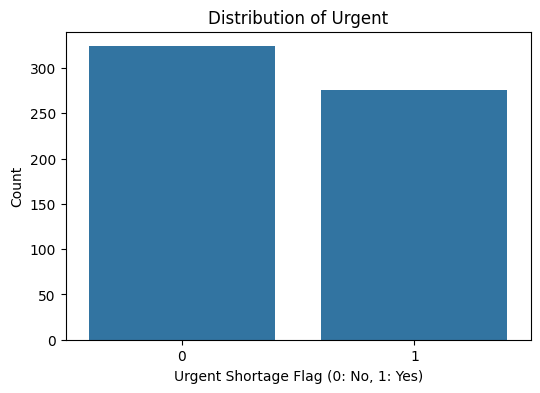

In [15]:
plt.figure(figsize=(6, 4))
sns.countplot(x="urgent_shortage_flag", data=df_clean)
plt.title("Distribution of Urgent")
plt.xlabel("Urgent Shortage Flag (0: No, 1: Yes)")
plt.ylabel("Count")
plt.show()
# Balanced

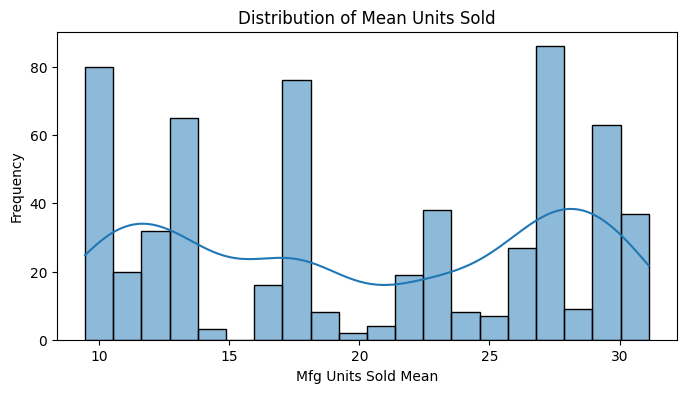

In [16]:
plt.figure(figsize=(8, 4))
sns.histplot(df_clean["mfg_units_sold_mean"], bins=20, kde=True)
plt.title("Distribution of Mean Units Sold")
plt.xlabel("Mfg Units Sold Mean")
plt.ylabel("Frequency")
plt.show()

It emphasizes the importance of using `StandardScaler` to standardize the ranges of numerical features before feeding them into the model.

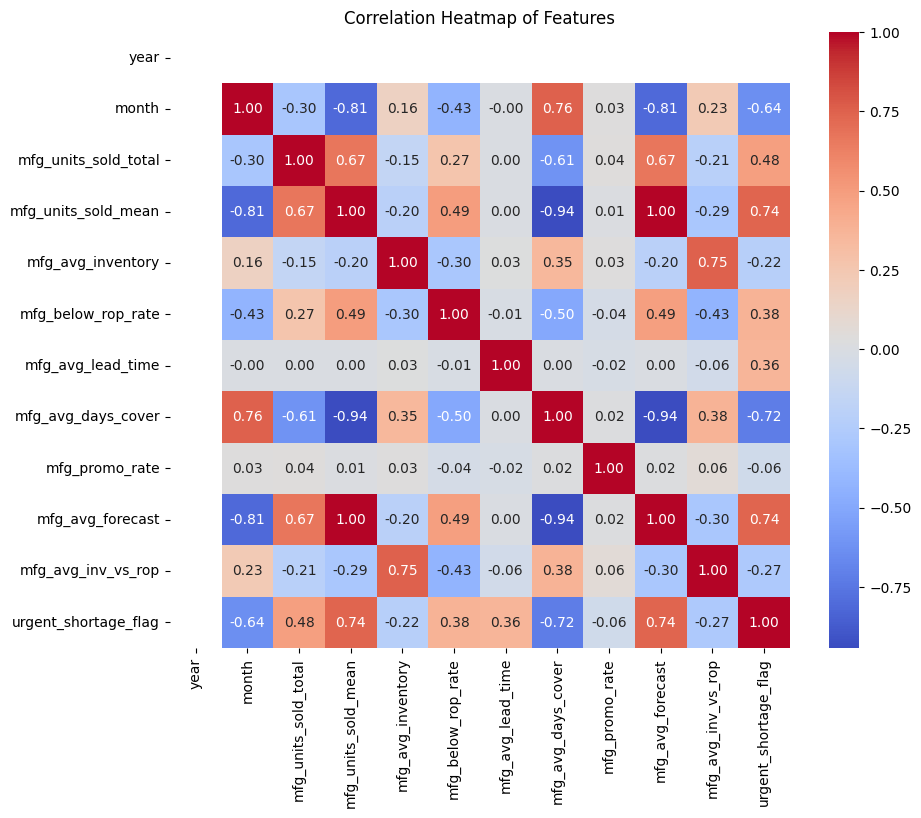

In [17]:
plt.figure(figsize=(10, 8))
corr = df_clean.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap of Features")
plt.show()

Practical Insight:

Identifying the most influential factors for shortage crises (`urgent_shortage_flag`):

Strong positive correlation (+0.74): Higher average sales (`mfg_units_sold_mean`) and higher forecasted demand (`mfg_avg_forecast`) directly increase the likelihood of a shortage crisis.

Strong negative correlation (-0.72): Increasing the number of days of inventory coverage (`mfg_avg_cover`) significantly reduces the risk of a shortage crisis.

Detecting Redundancy and Multicollinearity:

**importain note: A perfect correlation of +1.00 is observed between average sales (`mfg_units_sold_mean`) and forecasted demand (`mfg_avg_forecast`).**

Technical Decision: The existence of two variables with a correlation of 1.00 indicates that they provide identical information to the model. Consequently, one of these variables can be removed to reduce data volume and simplify the model.

In [18]:
# لأن وجود ميزتين بينهما ارتباط كامل بنسبة +1.00 يعني أنهما يقدمان نفس المعلومة تماماً للنموذج

df_clean = df_clean.drop(columns=["mfg_avg_forecast"])

#Spliting


In [74]:
X = df_clean.drop(columns=["urgent_shortage_flag"])
y = df_clean["urgent_shortage_flag"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (480, 10)
X_test shape: (120, 10)


In [22]:
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X_train.select_dtypes(include=["object"]).columns

In [23]:
num_pipeline = Pipeline(steps=[("scaler", StandardScaler())])

cat_pipeline = Pipeline(
    steps=[("encoder", OneHotEncoder(drop="first", handle_unknown="ignore"))]
)

In [24]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols),
    ]
)

# Random Forest

In [25]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                random_state=42, n_estimators=200, n_jobs=-1
            ),
        ),
    ]
)

In [27]:
#(Training Time)
start_time = time.time()
rf_pipeline.fit(X_train, y_train)
train_time = time.time() - start_time

In [28]:
train_acc = rf_pipeline.score(X_train, y_train)
test_acc = rf_pipeline.score(X_test, y_test)

In [29]:
y_pred_train = rf_pipeline.predict(X_train)
y_pred_test = rf_pipeline.predict(X_test)

In [32]:
print("--- Baseline Random Forest Evaluation Report ---")
print(f"Training Time: {train_time:.2f} seconds\n")

print(f"Train Accuracy: {train_acc * 100:.2f}%")
print(f"Test Accuracy: {test_acc * 100:.2f}%\n")

print("--- Classification Report (Train Data) ---")
print(classification_report(y_test, y_pred_test))

print("--- Classification Report (Test Data) ---")
print(classification_report(y_test, y_pred_test))

--- Baseline Random Forest Evaluation Report ---
Training Time: 0.50 seconds

Train Accuracy: 100.00%
Test Accuracy: 97.50%

--- Classification Report (Test Data) ---
              precision    recall  f1-score   support

           0       0.98      0.97      0.98        65
           1       0.96      0.98      0.97        55

    accuracy                           0.97       120
   macro avg       0.97      0.98      0.97       120
weighted avg       0.98      0.97      0.98       120



#XGB_Classifier

In [33]:
from xgboost import XGBClassifier

In [34]:
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                random_state=42,
                n_estimators=200,
                learning_rate=0.1,
                eval_metric="logloss",
                n_jobs=-1,
            ),
        ),
    ]
)

In [35]:
#(Training Time)
start_time = time.time()
xgb_pipeline.fit(X_train, y_train)
train_time = time.time() - start_time

In [36]:
train_acc = xgb_pipeline.score(X_train, y_train)
test_acc = xgb_pipeline.score(X_test, y_test)

In [37]:
y_pred_train = xgb_pipeline.predict(X_train)
y_pred_test = xgb_pipeline.predict(X_test)

In [38]:
print("--- Baseline XGBoost Evaluation Report ---")
print(f"Training Time: {train_time:.2f} seconds\n")

print(f"Train Accuracy: {train_acc * 100:.2f}%")
print(f"Test Accuracy: {test_acc * 100:.2f}%\n")

print("--- Classification Report (Test Data) ---")
print(classification_report(y_test, y_pred_test))

print("--- Confusion Matrix (Test Data) ---")
print(confusion_matrix(y_test, y_pred_test))

--- Baseline XGBoost Evaluation Report ---
Training Time: 0.13 seconds

Train Accuracy: 100.00%
Test Accuracy: 97.50%

--- Classification Report (Test Data) ---
              precision    recall  f1-score   support

           0       0.98      0.97      0.98        65
           1       0.96      0.98      0.97        55

    accuracy                           0.97       120
   macro avg       0.97      0.98      0.97       120
weighted avg       0.98      0.97      0.98       120

--- Confusion Matrix (Test Data) ---
[[63  2]
 [ 1 54]]


#Hyperparameter Tuning

In [46]:
from sklearn.model_selection import GridSearchCV

In [66]:
param_grid_controlled = {
    "classifier__max_depth": [2, 3, 4],  # تحديد عمق منخفض لمنع الحفظ الكامل
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__n_estimators": [100, 150],
    "classifier__min_child_weight": [
        3,
        5,
    ],  # اشتراط وزن أدنى للأوراق لمنع الـ Overfitting
    "classifier__subsample": [0.8, 1.0],
}

In [56]:
grid_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid_controlled,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

In [57]:
grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('scaler',
                                                                                          StandardScaler())]),
                                                                         Index(['year', 'month', 'mfg_units_sold_total', 'mfg_units_sold_mean',
       'mfg_avg_inventory', 'mfg_below_rop_rate', 'mfg_avg_lead_time',
       'mfg_avg_days_cover', 'mfg_promo_rate', 'mfg_avg_inv_vs_rop'],
      dtype='object')),...
                                                      min_child_weight=None,
                                                      missing=nan,
                                                      monotone_constraints=None,
                                                      multi_strategy=None,
                                                      n_estimators=200,
                                                      n_jobs=-1,
                                                      num_parallel_tree=None, ...))]),
             n_jobs=-1,
             param_grid={'classifier__learning_rate': [0.03, 0.05, 0.1],
                         'classifier__max_depth': [2, 3, 4],
                         'classifier__min_child_weight': [3, 5],
                         'classifier__n_estimators': [100, 150],
                         'classifier__subsample': [0.8, 1.0]},
             scoring='accuracy')

In [58]:
best_xgb_pipeline = grid_search.best_estimator_

In [59]:
y_pred_train_tuned = best_xgb_pipeline.predict(X_train)
y_pred_test_tuned = best_xgb_pipeline.predict(X_test)

In [60]:
print("Best Hyperparameters:", grid_search.best_params_)
print(f"Best CV Score: {grid_search.best_score_ * 100:.2f}%\n")

print("--- Tuned XGBoost Evaluation Report ---")
print(
    f"Train Accuracy: {best_xgb_pipeline.score(X_train, y_train) * 100:.2f}%"
)
print(f"Test Accuracy: {best_xgb_pipeline.score(X_test, y_test) * 100:.2f}%\n")

print("--- Classification Report (Test Data) ---")
print(classification_report(y_test, y_pred_test_tuned))

print("--- Confusion Matrix (Test Data) ---")
print(confusion_matrix(y_test, y_pred_test_tuned))

Best Hyperparameters: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 100, 'classifier__subsample': 0.8}
Best CV Score: 98.12%

--- Tuned XGBoost Evaluation Report ---
Train Accuracy: 99.79%
Test Accuracy: 97.50%

--- Classification Report (Test Data) ---
              precision    recall  f1-score   support

           0       0.98      0.97      0.98        65
           1       0.96      0.98      0.97        55

    accuracy                           0.97       120
   macro avg       0.97      0.98      0.97       120
weighted avg       0.98      0.97      0.98       120

--- Confusion Matrix (Test Data) ---
[[63  2]
 [ 1 54]]


# Feature Importance

In [61]:
importances = best_xgb_pipeline.named_steps["classifier"].feature_importances_

In [62]:
feature_names = num_cols.tolist()

In [63]:
feature_imp_df = pd.DataFrame(
    {"Feature": feature_names, "Importance": importances}
).sort_values(by="Importance", ascending=False)

/tmp/ipykernel_4267/2054568058.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


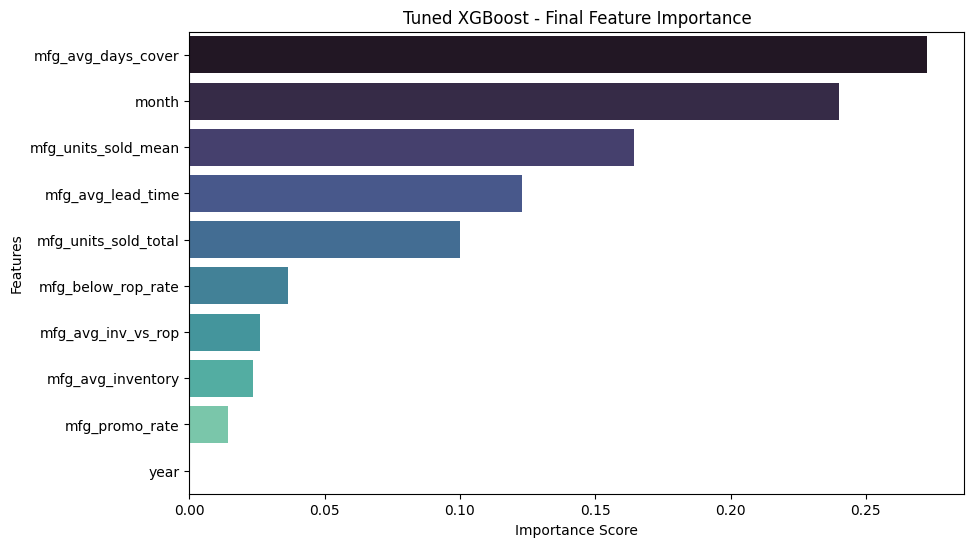

In [64]:
plt.figure(figsize=(10, 6))
sns.barplot(
    x="Importance", y="Feature", data=feature_imp_df, palette="mako"
)
plt.title("Tuned XGBoost - Final Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

In [65]:
print("--- Final Model Feature Importances ---")
print(feature_imp_df.to_string(index=False))

--- Final Model Feature Importances ---
             Feature  Importance
  mfg_avg_days_cover    0.272768
               month    0.240008
 mfg_units_sold_mean    0.164301
   mfg_avg_lead_time    0.122777
mfg_units_sold_total    0.099943
  mfg_below_rop_rate    0.036363
  mfg_avg_inv_vs_rop    0.025921
   mfg_avg_inventory    0.023609
      mfg_promo_rate    0.014309
                year    0.000000


**Breaking down the top-ranking factors (from highest to lowest impact)**:

`mfg_avg_days_cover` (approx. 27.3%):
The primary driver in the decision-making process. This variable represents the number of days that current inventory can cover sales.
 When the model detects that this coverage period is very short or limited, it immediately identifies that the product is at risk of an imminent stockout.

 `month` (approx. 24.0%):
Seasonality. The model has determined that the specific month plays a significant role; certain times of the year see an increase in demand and sales, which in turn raises the risk of shortages.

 `mfg_units_sold_mean` (approx. 16.4%):
Average sales. The higher the average sales for a given product, the more closely the model monitors it.

 `mfg_avg_lead_time` (approx. 12.3%):
Supplier lead time. This refers to the time it takes for shipments to arrive; if the lead time is long, even a minor delay can immediately trigger a stockout crisis.

 `mfg_units_sold_total` (approx. 10.0%):The total cumulative sales for the product.



**Weak and Negligible Factors: Minor Operational Factors (between 1.4% and 3.6%)**:

Variables such as the ROP (Reorder Point) bypass rate (`mfg_below_rop_rate`), inventory levels,

 and the promotion rate (`mfg_promo_rate`) have a very limited impact on the model's decision-making.

Year (0.0%):
The "year" variable has absolutely no predictive value; this is because supply chain crises are driven by sales patterns, seasonality, and the specific month—the model does not distinguish which year these patterns occur in.


**Business Insight**:

**The first four factors** alone—days of coverage, month, average sales, and lead time—account for over 80% of the model’s decision-making. This serves as excellent proof for management or the client that the model truly understands supply chain business dynamics and is grounded in real operational metrics, rather than relying on arbitrary numbers.

#Verification code

In [68]:
# 1. اقتطاع صف واحد كعينّة اختبار جديدة من X_test
sample_data = X_test.iloc[:1]

# 2. التنبؤ بالفئة (0: لا يوجد أزمة عاجلة | 1: يوجد أزمة عاجلة)
sample_pred = best_xgb_pipeline.predict(sample_data)

# 3. حساب احتمالية وقوع الأزمة بالظبط (Probability Score)
sample_proba = best_xgb_pipeline.predict_proba(sample_data)

print("--- Sample Prediction Test ---")
print(f"Predicted Class: {sample_pred[0]}")
print(
    f"Shortage Probability: {sample_proba[0][1] * 100:.2f}%"
)

--- Sample Prediction Test ---
Predicted Class: 0
Shortage Probability: 0.80%


# Save and load model

In [69]:
import joblib

In [70]:
joblib.dump(best_xgb_pipeline, "best_xgb_disruption_model.joblib")

['best_xgb_disruption_model.joblib']

In [71]:
loaded_xgb_pipeline = joblib.load("best_xgb_disruption_model.joblib")

In [72]:
y_pred_loaded = loaded_xgb_pipeline.predict(X_test)